# N135 — causal label-free MPC on correlated BDD video

Rendered snapshot: **2026-11-03T08:22:29.250882+00:00**. Status: **complete**.
This generated notebook is refreshed independently of training. Reopen/reload it for new saved outputs, or **Run All** to read the latest committed checkpoints.

**91,968 real frames from 958 clips, preserved in source timestamp order within each clip.** This is a constructed sequence of drives. No clip IDs, boundaries, phase flags, future frames or task labels enter the controller. Histories and learner state continue through joins.

[Frozen protocol](../../../docs/project-plan/causal-temporal-mpc.md) · [Live report](../../../outputs/causal-temporal-mpc/20261103-n135/live.html)


In [1]:
from pathlib import Path
import sys
PROJECT = Path('C:\\CAFL-E\\project\\cafl4ds')
if str(PROJECT) not in sys.path:
    sys.path.insert(0, str(PROJECT))
from scripts.build_causal_temporal_mpc_notebook import (
    snapshot, task_table, accuracy_figure, cells_figure, controller_figure,
    health_figure, plant_table, plant_figure, figure_png,
)
from IPython.display import Image, display, Markdown
RUN = Path('C:\\CAFL-E\\project\\cafl4ds\\outputs\\causal-temporal-mpc\\20261103-n135')
state = snapshot(RUN)
def show(fig):
    display(Image(data=figure_png(fig)))
print(state['status'])


{
  "stage": "complete",
  "running": false,
  "updated": 1793683715.4108603
}


## Completed-run interpretation

All four arms finished 91,968 arrivals without numerical failures. **The plant-learning and anti-stall repairs worked; the MPC did not beat the simple paced control on the task.**

| Endpoint | Balanced accuracy % | Worst-cell % | CE |
|---|---:|---:|---:|
| Frozen parent | 63.024 | 49.824 | 0.74112 |
| MPC | 59.911 | 47.020 | 0.72689 |
| Full quarter | 60.747 | 49.163 | 0.71223 |
| Full nominal | 58.394 | 49.236 | 0.69307 |
| Paced quarter | 61.429 | 50.726 | 0.68946 |

Paced quarter beats MPC in balanced accuracy at all 16 common post-parent checkpoints; its final advantages are 1.518 pp balanced accuracy, 3.706 pp worst-cell accuracy and 0.03744 lower CE. All adaptive endpoints lose balanced accuracy versus the parent, though paced improves worst-cell accuracy and CE. Early gains exist: full nominal reaches 64.934% at 6,144 arrivals, then declines. These retrospective peaks cannot be used as label-free stopping rules.

**Important scope correction:** every one of the 958 online clips carries a highway keyframe annotation: 479 daytime and 479 night, verified against the official local label JSONs after completion. The evaluation is city/highway balanced. This is a highway-adaptation/retention test, not broad scene-mixed BDD. This limitation should have been disclosed at launch. Keyframe labels do not label every video frame, and no source annotations entered runtime control.

One-step health forecast MSE improves 57.7% / 59.4% / 60.4% over persistence for rank / reconstruction / variance; H2 improvements are 52.5% / 54.4% / 49.6%. Reconstruction skill is positive throughout the run. MPC commits 41,162 updates, with no hold gap longer than three arrivals. Predictor feedback does not freeze.

The failure is the task relevance of the optimized proxy. J improves 36.9%, reconstruction improves 24.9%, rank nearly doubles, yet balanced accuracy drops 3.11 pp. Both geometry penalties are inactive on 94.75% of arrivals and throughout the final 16,384: late control mostly optimizes reconstruction. A balanced unlabeled monitoring bank does not by itself preserve city/highway discrimination.

MPC uses 2.62 times paced quarter's cumulative LR budget and 1.79 times its learner updates. Nominal steps supply 51.1% of MPC's LR budget, making the larger-rate action a plausible contributor to damage. This is not an isolated causal test of rate versus selection. Recorded operational cost is about 109 minutes versus 25 minutes for paced, and 102 minutes for full quarter. There is no measured efficiency win here.

**Next:** retain paced quarter and the frozen parent as incumbents; isolate MPC selection under a matched quarter-rate/update budget before another long run. Qualify a label-free retention intervention/signal using copied, matched-budget trials and offline task evaluation. Bigger health predictors or longer planning horizons are not the priority supported by this result. One training seed/order and inspected validation data limit generalization.

Detailed calculations: `C:/CAFL-E/analysis/2026-11-03-n135-results/analysis.json`.


## Task accuracy and retention

| Arm | Arrivals | Updates | Probe at | Linear accuracy % | Δ parent pp | Worst-cell % | CE | LR budget / nominal full |
|---|---:|---:|---:|---:|---:|---:|---:|---:|
| mpc | 91,968 | 41,162 | 91,968 | 59.911 | -3.113 | 47.020 | 0.726893 | 16.38% |
| full_quarter | 91,968 | 91,968 | 91,968 | 60.747 | -2.277 | 49.163 | 0.712233 | 25.00% |
| full_nominal | 91,968 | 91,968 | 91,968 | 58.394 | -4.630 | 49.236 | 0.693073 | 100.00% |
| paced_quarter | 91,968 | 22,992 | 91,968 | 61.429 | -1.595 | 50.726 | 0.689456 | 6.25% |

**“Probe at” is the evaluation horizon.** A row with probe 0 shows only the common parent; it is not post-training accuracy. Independent readouts occur every 6,144 arrivals, at the 8,192 prefix and at the endpoint. Labels fit evaluation readers only; they do not fit or control MPC.

All arms share parent/order/augmentation seeds. LR dose and operational work differ; these are not equal-dose or equal-compute comparisons. One historical stream/seed and repeatedly inspected validation data do not establish independent replication.


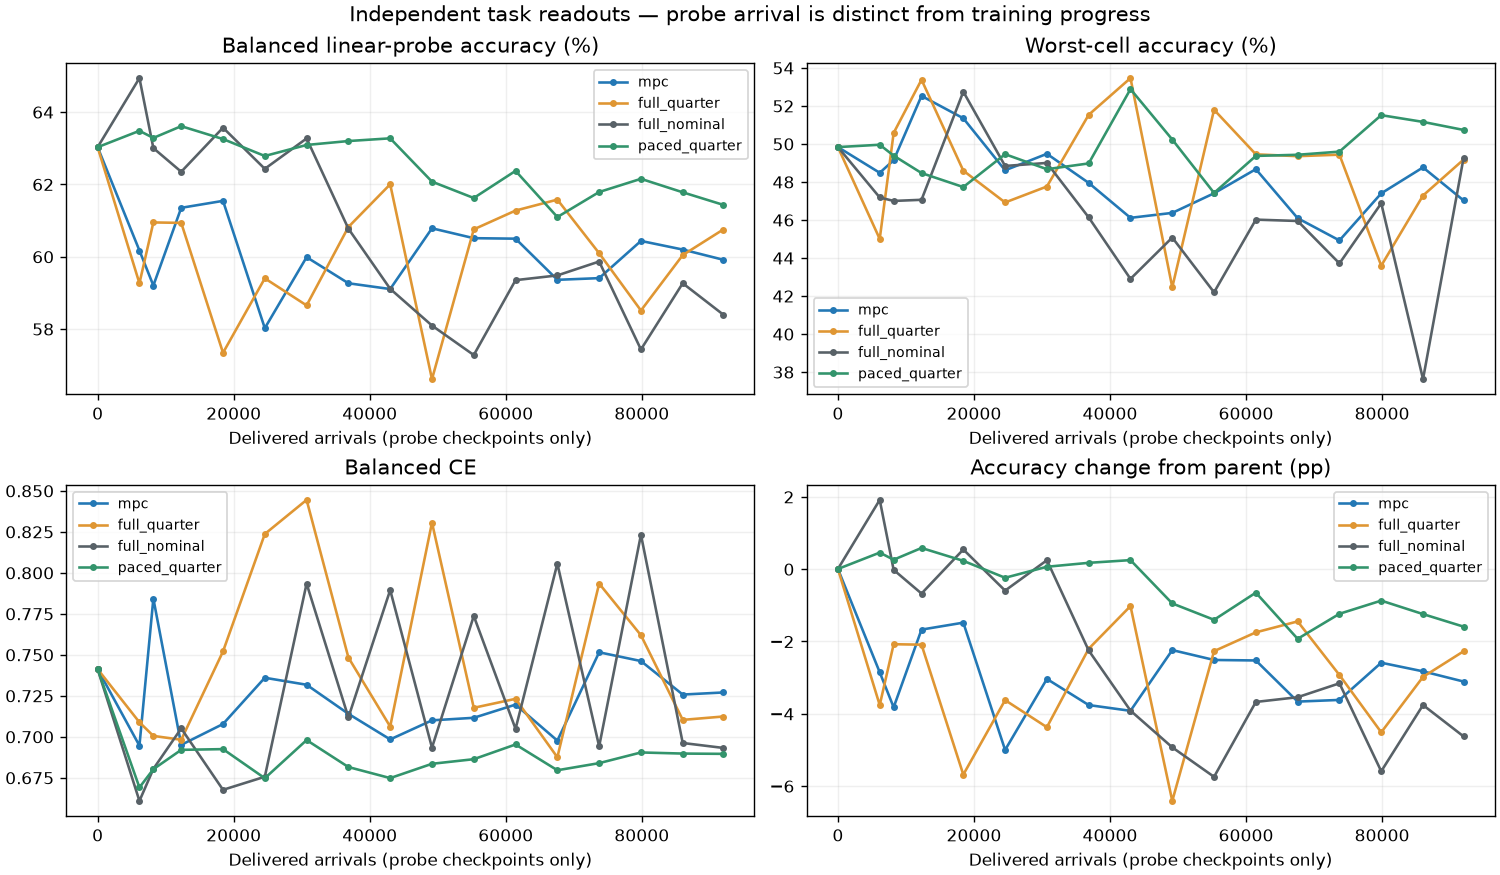

In [2]:
display(Markdown(task_table(state)))
show(accuracy_figure(state))


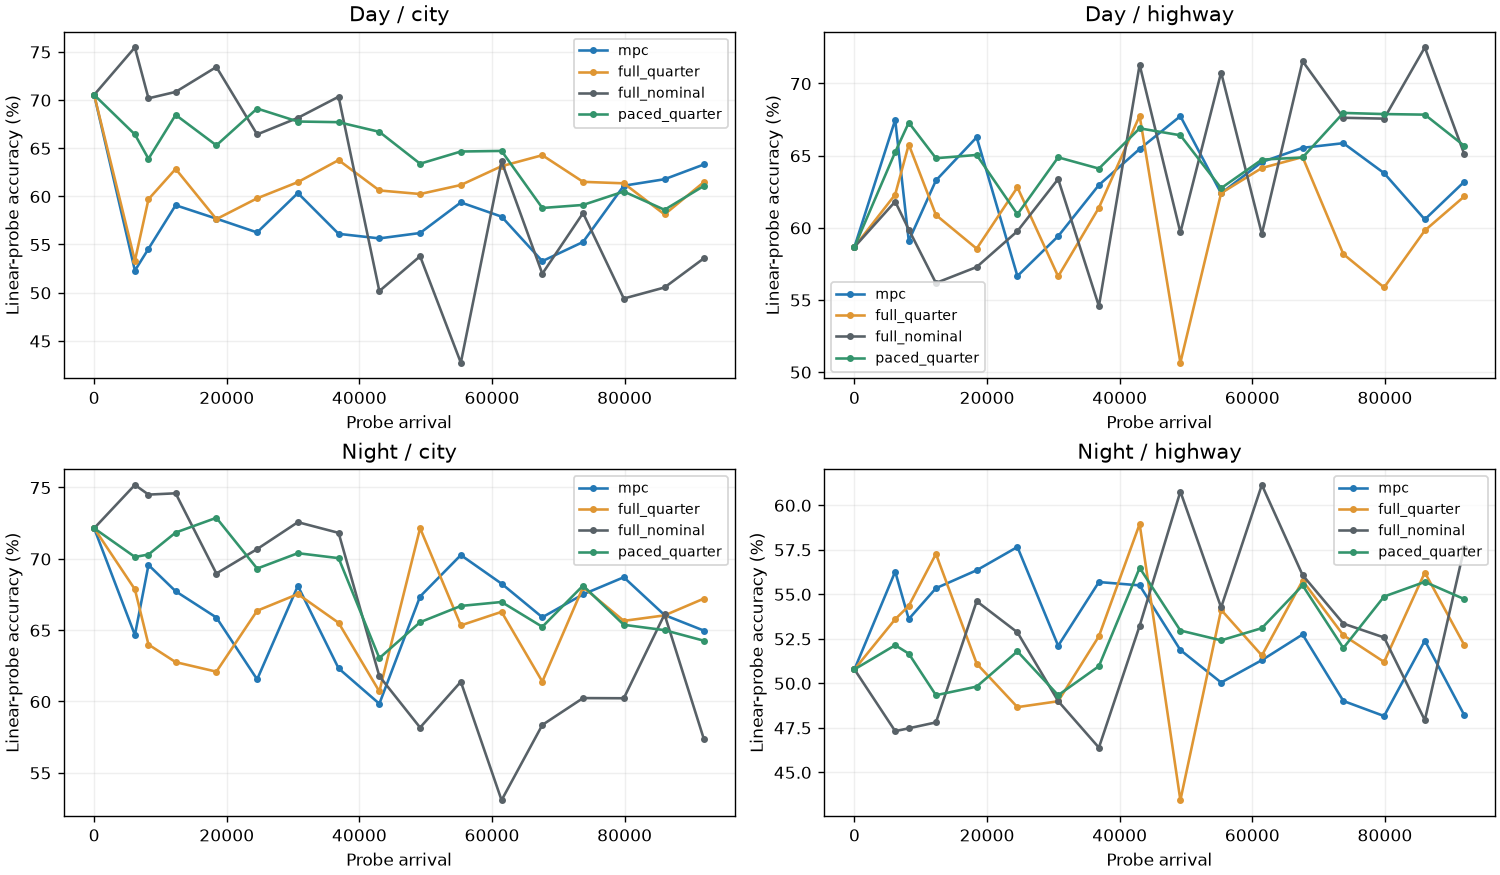

In [3]:
show(cells_figure(state))


## Controller and plant model

**Observed state:** 88 current/past-only measurements: rank, reconstruction, variance and histories; previous physical actions; current RGB/edge/embedding/projection descriptors; distances and reconstruction on unlabeled memory clusters. No gradient preview, stream age, filenames, scene labels or clip position.

**Plant:** action-interacted ridge predicts three one-step health changes. With standardized features $\phi(x)$ and physical rate $a$, its raw response is $\widehat{\Delta s}=[a\phi(x),a^2\phi(x)]W$ (with fitted output scaling). Bounded per-action/output calibration multiplies that response by gains in $[0,1]$, learned from past executed responses. Ridge evidence and calibration forget with a 256-update half-life. Holds are exact identity; imagined steps never teach the predictor.

**Planner:** enumerate 16 pairs of rates $\{0,1/16,1/4,1\}$, minimize summed next-two-state objective, execute the first action and remeasure. Future image context is approximated by persistence, without a future-image preview.

$$J(s)=L/L_{ref}+0.25\max(0,1-r/r_{ref})+0.25\max(0,1-v/v_{ref}).$$

This is a reconstruction/health objective, not an established semantic-retention signal. Geometry penalties can become inactive. There is no task-CE veto. Five-percent positive exploration and one quarter-rate-or-higher update per four finite arrivals prevent indefinite hold. Numerical failure alone triggers rollback and cooldown.

**Gradients:** accepted MAE training uses self-supervised gradients and AdamW, with clipping. Gradient norms are diagnostics and numerical checks; they do not select actions. Predictor fitting is ridge adaptation, not backpropagation.


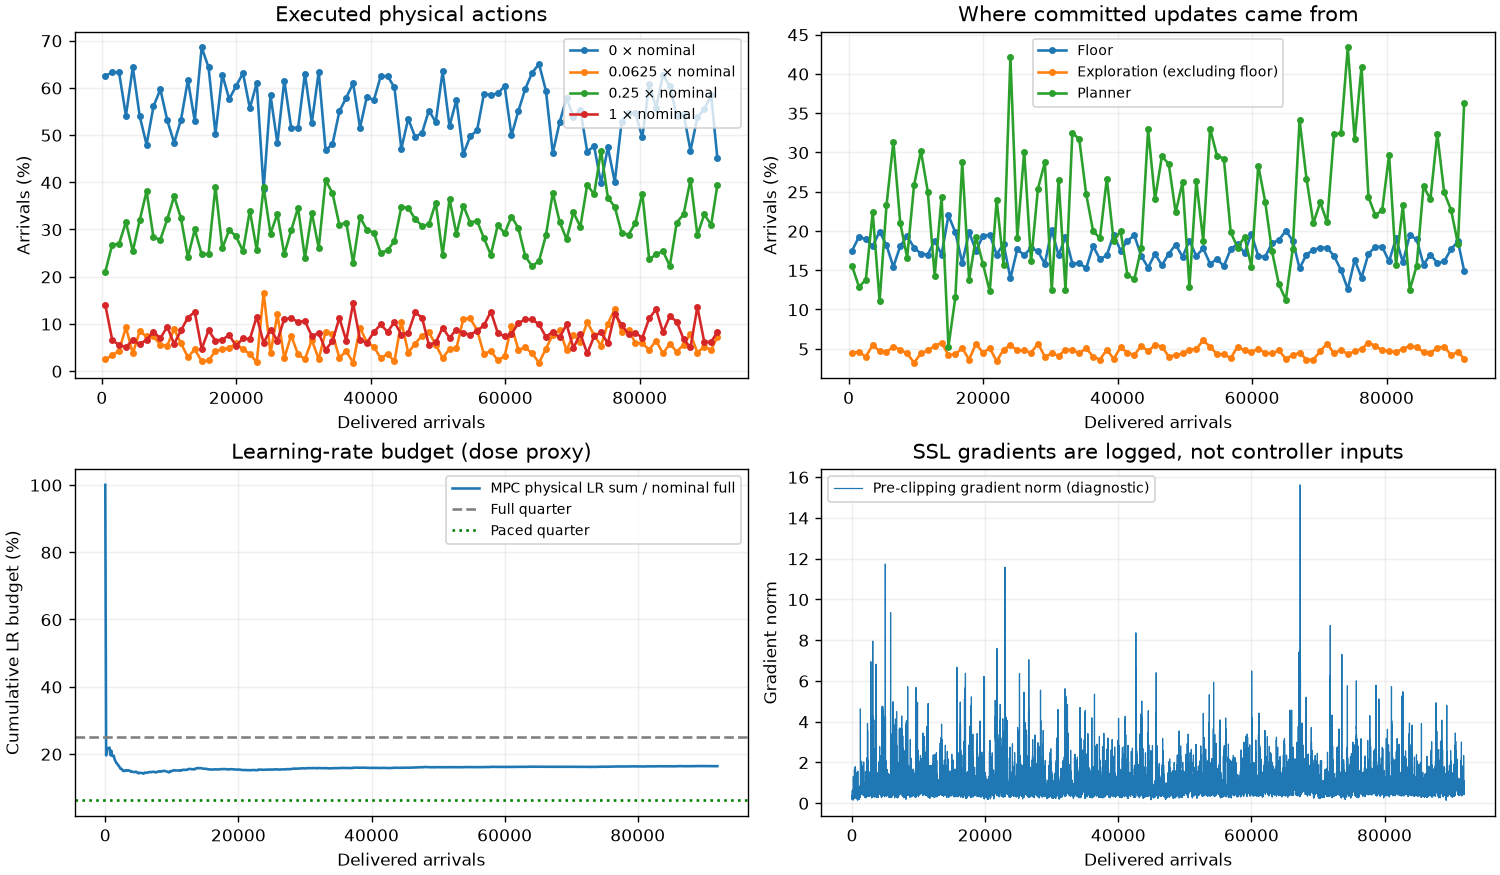

In [4]:
show(controller_figure(state))


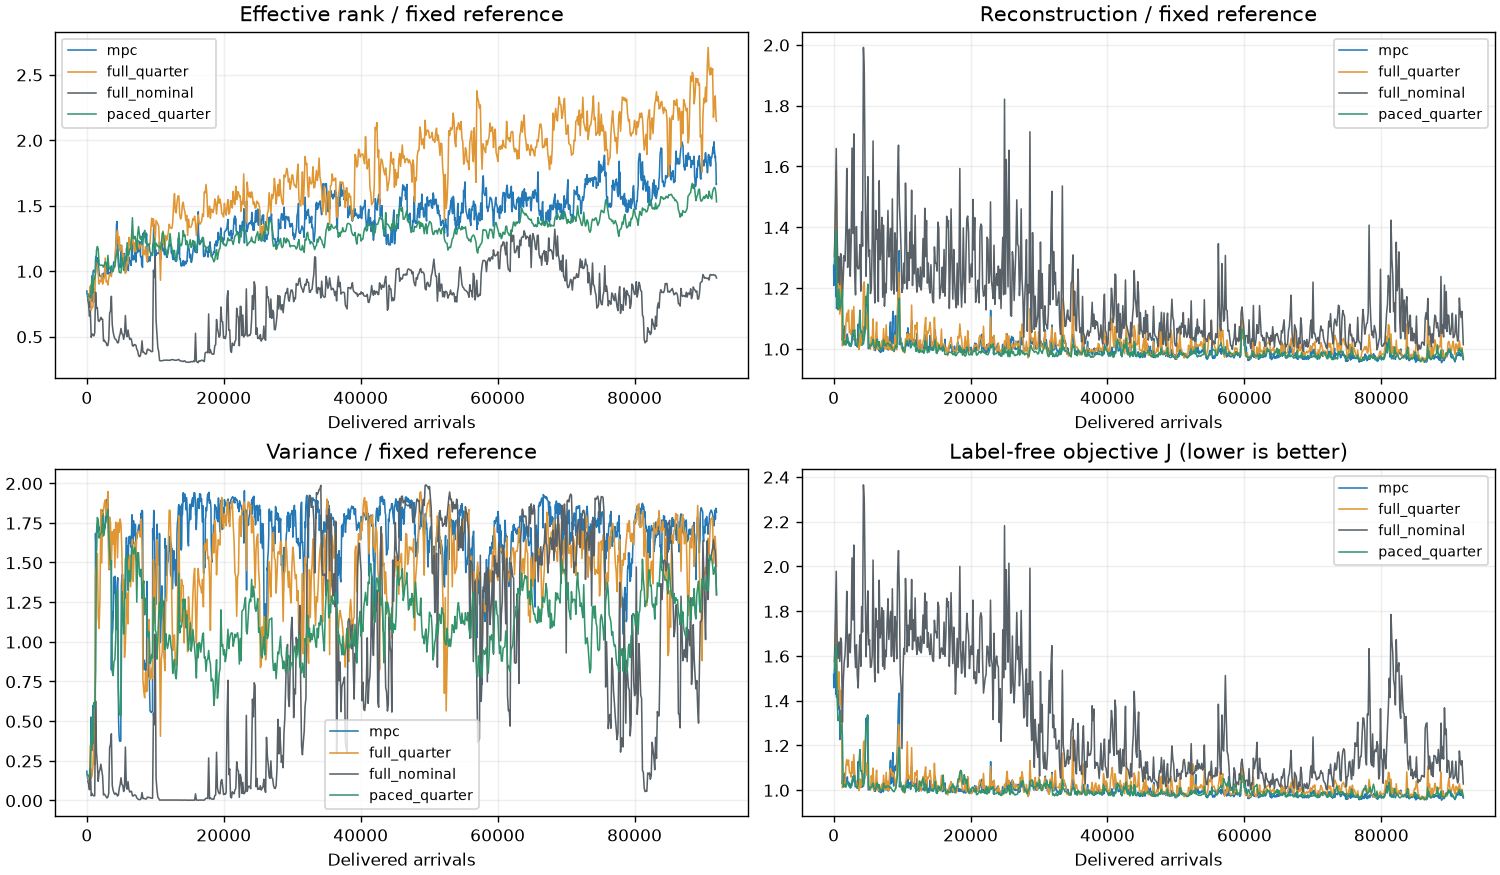

In [5]:
show(health_figure(state))


## Does the plant forecast work?

| Output | Calibrated RMSE | Raw online RMSE | Frozen RMSE | Persistence RMSE | Calibrated MSE gain | Direction accuracy |
|---|---:|---:|---:|---:|---:|---:|
| Rank | 0.00815202 | 0.00870458 | 0.033153 | 0.0125299 | +57.7% | 76.4% |
| Reconstruction | 0.000768334 | 0.000833937 | 0.00380344 | 0.00120645 | +59.4% | 66.7% |
| Variance | 2.35764e-05 | 2.50079e-05 | 4.45864e-05 | 3.74774e-05 | +60.4% | 74.7% |

Measured positive transitions: 41,162. Identity holds excluded.

| Physical rate | Positive transitions | Reconstruction MSE gain |
|---|---:|---:|
| 0.0625 | 5,310 | +26.7% |
| 0.25 | 28,160 | +42.3% |
| 1.0 | 7,692 | +62.2% |

Raw online, calibrated online and frozen-offline predictions are scored on the **same actual positive updates**, before feedback. Persistence predicts no change. Better forecast MSE is not evidence by itself of better counterfactual action ranking or task accuracy.


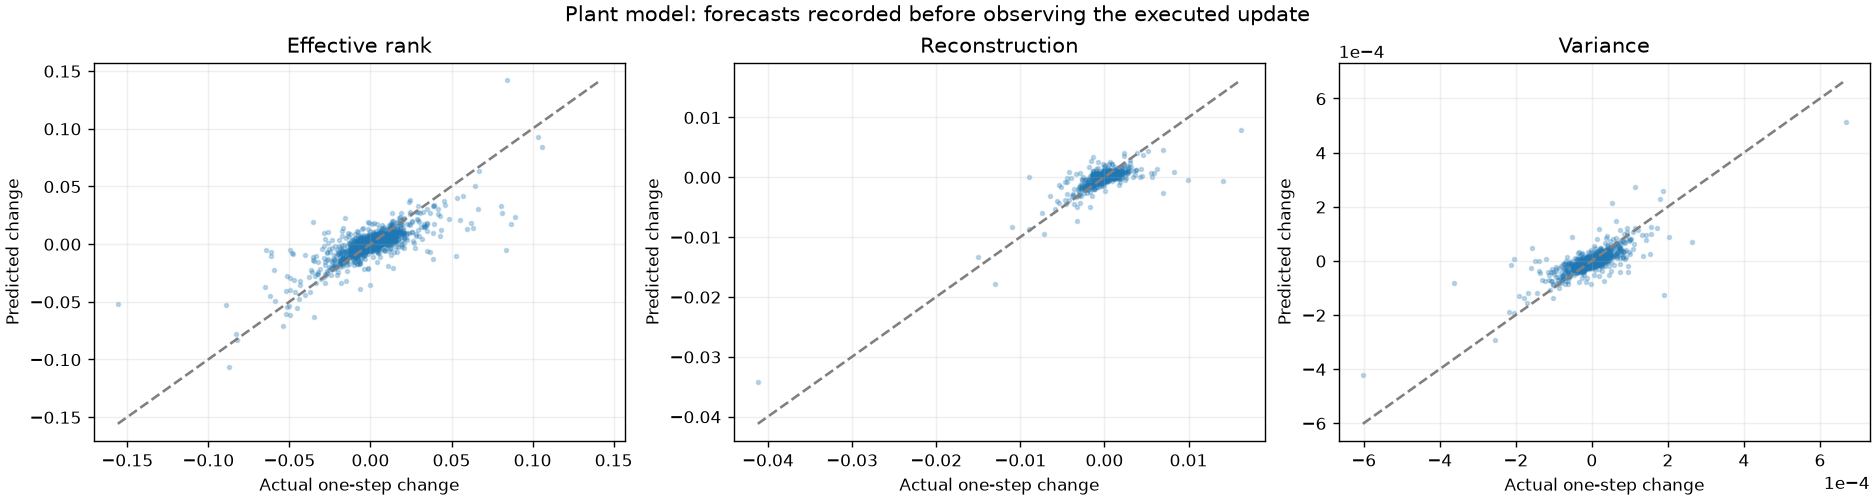

In [6]:
display(Markdown(plant_table(state)))
show(plant_figure(state))


## Verification and artifacts

- Verified container/frame hashes and increasing source indices/PTS; offline and evaluation separation.
- Eight targeted tests; exact archived causal feature fixture; GPU resume and numerical rollback/cooldown checks.
- Live-head replay verifies forecasts, decisions and calibration solely from logged past observations.
- Training continues under its original frozen source lock. This notebook companion performs no training or controller mutation.


In [7]:
import json
for name in ('intake-verification.json', 'preflight.json', 'prequential-replay-verification.json'):
    record = json.loads((RUN / name).read_text())
    print(name, {k: v for k, v in record.items() if k not in ('manifest_hashes', 'checks')})


{
  "intake-verification.json": {
    "passed": true,
    "clips": 958,
    "frames": 91968,
    "bank_clips_removed": 0,
    "offline_overlap_clips": 0,
    "evaluation_overlap_clips": 0,
    "evaluation_exact_pixel_overlap": 0,
    "bank_online_pixel_overlap": 0,
    "all_source_frame_indices_increasing": true,
    "all_source_pts_increasing": true,
    "frame_manifest_hashes_verified": true,
    "within_clip_adjacent_rgb_difference": 0.01593852040023972,
    "within_clip_shuffled_rgb_difference": 0.06960412325182609,
    "spans_seconds": [
      5.938333,
      6.003333
    ],
    "seconds": 22.698476999998093,
    "online_unique_pixels": 91968
  },
  "preflight.json": {
    "passed": true,
    "real_gpu": true,
    "online_scientific_arrivals_used": 0
  },
  "prequential-replay-verification.json": {
    "passed": true,
    "arrivals": 2048,
    "updates": 760,
    "replayed_all_first_second_forecasts": true,
    "replayed_all_actions_and_floor": true,
    "exact_final_predictor_and